In [1]:
%pip install torchxrayvision torch torchvision pillow numpy pandas matplotlib

  Using cached torchxrayvision-1.5.5-py3-none-any.whl.metadata (18 kB)
  Using cached scikit_image-0.26.0-cp311-cp311-win_amd64.whl.metadata (15 kB)
  Using cached tifffile-2026.3.3-py3-none-any.whl.metadata (31 kB)
Using cached torchxrayvision-1.5.5-py3-none-any.whl (29.0 MB)
Using cached scikit_image-0.26.0-cp311-cp311-win_amd64.whl (11.9 MB)
Using cached tifffile-2026.3.3-py3-none-any.whl (243 kB)

   ----------------------------------------  0/10 [urllib3]
   ----------------------------------------  0/10 [urllib3]
   ----------------------------------------  0/10 [urllib3]
   ----------------------------------------  0/10 [urllib3]
   ----------------------------------------  0/10 [urllib3]
   ---- -----------------------------------  1/10 [tifffile]
   ---- -----------------------------------  1/10 [tifffile]
   ---- -----------------------------------  1/10 [tifffile]
   ---- -----------------------------------  1/10 [tifffile]
   ---- -----------------------------------  1/10 [

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torchxrayvision as xrv

ROOT = Path(r"C:\projects\Final Year Project")

METADATA_PATH = (
    ROOT / "Metadata" / "preprocessing_metadata.csv"
)

RESULTS_DIR = ROOT / "Segmentation_Validation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

metadata = pd.read_csv(METADATA_PATH)
display(metadata.head())

c:\projects\FYP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cu126
Device: cuda
CUDA available: True


,image_id,domain,class_name,label,original_path,processed_path,width,height,channels
0,000001.png,Domain1_NLM,Normal,0,C:\projects\Final Year Project\Dataset\Domain ...,C:\projects\Final Year Project\Preprocessed_Da...,512,512,1
1,000002.png,Domain1_NLM,Normal,0,C:\projects\Final Year Project\Dataset\Domain ...,C:\projects\Final Year Project\Preprocessed_Da...,512,512,1
2,000003.png,Domain1_NLM,Normal,0,C:\projects\Final Year Project\Dataset\Domain ...,C:\projects\Final Year Project\Preprocessed_Da...,512,512,1
3,000004.png,Domain1_NLM,Normal,0,C:\projects\Final Year Project\Dataset\Domain ...,C:\projects\Final Year Project\Preprocessed_Da...,512,512,1
4,000005.png,Domain1_NLM,Normal,0,C:\projects\Final Year Project\Dataset\Domain ...,C:\projects\Final Year Project\Preprocessed_Da...,512,512,1


In [3]:
seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model = seg_model.to(device)
seg_model.eval()

print("Model loaded.")
print("Targets:", seg_model.targets)

Model loaded.
Targets: ['Left Clavicle', 'Right Clavicle', 'Left Scapula', 'Right Scapula', 'Left Lung', 'Right Lung', 'Left Hilus Pulmonis', 'Right Hilus Pulmonis', 'Heart', 'Aorta', 'Facies Diaphragmatica', 'Mediastinum', 'Weasand', 'Spine']


In [4]:
left_lung_idx = seg_model.targets.index("Left Lung")
right_lung_idx = seg_model.targets.index("Right Lung")

print("Left lung channel:", left_lung_idx)
print("Right lung channel:", right_lung_idx)

Left lung channel: 4
Right lung channel: 5


In [ ]:
sample_df = (
    metadata.groupby(["domain", "label"], group_keys=False)
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)

print("Total sampled images:", len(sample_df))
print("\nSamples per domain and class:")
print(
    sample_df.groupby(["domain", "class_name"]).size()
)

Total sampled images: 40

Samples per domain and class:
domain            class_name  
Domain1_NLM       Normal          10
                  Tuberculosis    10
Domain2_Mendeley  Normal          10
                  Tuberculosis    10
dtype: int64


In [9]:
from pathlib import Path

sample_df["file_exists"] = sample_df["processed_path"].apply(
    lambda p: Path(p).is_file()
)

print("Existing files:", sample_df["file_exists"].sum())
print("Missing files:", (~sample_df["file_exists"]).sum())

assert sample_df["file_exists"].all(), "Some sampled images are missing!"

Existing files: 40
Missing files: 0


In [10]:
import torch
import torchxrayvision as xrv
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load pretrained PSPNet
seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model = seg_model.to(device)
seg_model.eval()

# Find the lung output channels
print("Available segmentation targets:")
print(seg_model.targets)

left_lung_idx = seg_model.targets.index("Left Lung")
right_lung_idx = seg_model.targets.index("Right Lung")

print("\nLeft lung channel:", left_lung_idx)
print("Right lung channel:", right_lung_idx)

Device: cuda
Available segmentation targets:
['Left Clavicle', 'Right Clavicle', 'Left Scapula', 'Right Scapula', 'Left Lung', 'Right Lung', 'Left Hilus Pulmonis', 'Right Hilus Pulmonis', 'Heart', 'Aorta', 'Facies Diaphragmatica', 'Mediastinum', 'Weasand', 'Spine']

Left lung channel: 4
Right lung channel: 5


In [11]:
def load_pspnet_input(image_path):
    with Image.open(image_path) as img:
        img = img.convert("L").resize((512, 512))
        image = np.asarray(img, dtype=np.float32)

    # TorchXRayVision normalization
    image = xrv.datasets.normalize(image, 255)

    # Shape: batch, channel, height, width
    tensor = torch.from_numpy(image).unsqueeze(0).unsqueeze(0)

    return tensor.to(device)


test_path = sample_df.iloc[0]["processed_path"]
input_tensor = load_pspnet_input(test_path)

print("Input shape:", tuple(input_tensor.shape))
print("Input range:", input_tensor.min().item(), "to", input_tensor.max().item())

with torch.no_grad():
    output = seg_model(input_tensor)

print("Output shape:", tuple(output.shape))
print("Output range:", output.min().item(), "to", output.max().item())

Input shape: (1, 1, 512, 512)
Input range: -1024.0 to 919.5921630859375
Output shape: (1, 14, 512, 512)
Output range: -20.22515106201172 to 11.778753280639648


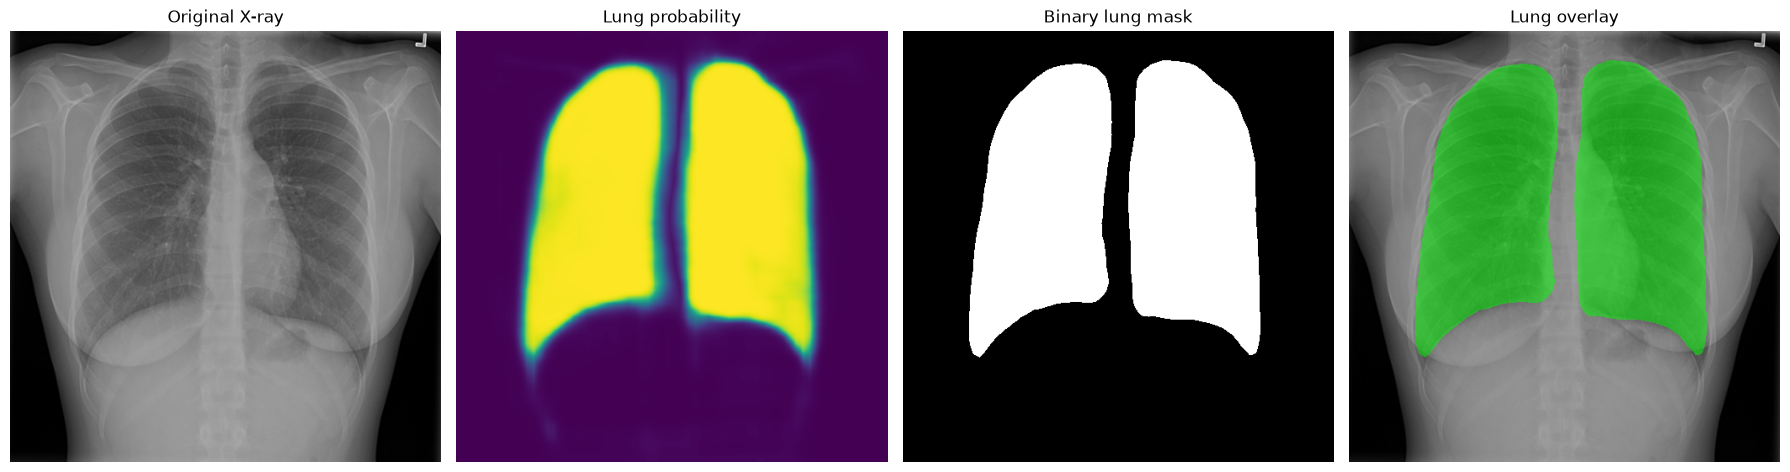

Lung probability range: 0.00019588024588301778 to 0.9999923706054688
Lung area percentage: 32.45 %


In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

test_path = sample_df.iloc[0]["processed_path"]

# Load original preprocessed image for display
original = np.array(
    Image.open(test_path).convert("L").resize((512, 512))
)

# Get PSPNet predictions
input_tensor = load_pspnet_input(test_path)

with torch.no_grad():
    logits = seg_model(input_tensor)

# Convert logits to probabilities
probabilities = torch.sigmoid(logits)[0].cpu().numpy()

# Extract left and right lung channels
left_lung = probabilities[left_lung_idx]
right_lung = probabilities[right_lung_idx]

# Combine the lung probabilities
lung_probability = np.maximum(left_lung, right_lung)

# Initial threshold for visual inspection only
threshold = 0.5
lung_mask = lung_probability >= threshold

# Create overlay
overlay = np.stack([original, original, original], axis=-1).astype(np.float32)
overlay[lung_mask] = (
    0.5 * overlay[lung_mask]
    + 0.5 * np.array([0, 255, 0], dtype=np.float32)
)
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

# Display results
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(lung_probability, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Lung probability")

axes[2].imshow(lung_mask, cmap="gray")
axes[2].set_title("Binary lung mask")

axes[3].imshow(overlay)
axes[3].set_title("Lung overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Lung probability range:",
      float(lung_probability.min()),
      "to", float(lung_probability.max()))

print("Lung area percentage:",
      round(100 * lung_mask.mean(), 2), "%")